# Assignment 2: Statistical Inference and Predictive Analysis

### Inference: Do home teams win more than 50% of games? 
### Prediction: Can we predict whether the home team wins using only information available before the game? 

In [2]:
# Import and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

team = pd.read_csv('teamstatistics.csv')

print("Data set raw shape:", team.shape)

# Same cleaning decisions as Assignment 1
team["gameDate"] = pd.to_datetime(team["gameDate"])
d = team[(team["gameDate"] >= "2021-10-01") & (team["gameDate"] < "2026-10-02")]
d = d[d["gameId"] // 1000000 == 22]          # 22 = regular season (gameType is null for 2021-22)
d = d.dropna(subset=["win"])                  # unplayed / postponed games
d = d[d["teamScore"] > 0].copy()              # drop invalid 0-0 rows
d = d.sort_values(["teamId", "gameDate"]).reset_index(drop=True)
print("Clean team-games:", len(d), "| games:", d["gameId"].nunique(), "| teams:", d["teamName"].nunique())
print("From Dates:", d["gameDate"].min().date(), "to", d["gameDate"].max().date())

Data set raw shape: (146768, 59)
Clean team-games: 12288 | games: 6144 | teams: 30
From Dates: 2021-10-19 to 2026-04-12


## Inference: Do home teams wins more than 50% of games? Is there a home court advantage?

**Estimation target:** the population proportion *p* of games won by the home team.

**Hypotheses**
- H0: p = 0.50 (home court gives no advantage)
- Ha: p > 0.50 (home teams win more than half of their games)

**Method:** one-sample z-test for a proportion, with a 95% confidence interval for *p*.

**Rationale:** the outcome is binary (home win or not) and the question compares one proportion to a fixed benchmark.

**Assumptions**
1. Independence: The raw data has two rows per game (one per team), which would double-count each game. I use **one row per game** (the home team's row).
2. Sample size: nxp0 and nx(1-p0) are both at least 10 (checked below).
3. Sampling: These are all regular-season games from five seasons, not a random sample of NBA history, so the result applies to this league and period only.

In [3]:
# For inference test 

#One row per game
home = d[d["home"] == 1]
n = len(home)
x = int(home["win"].sum())
p_hat = x / n
p0 = 0.5

print("One row per game?", home["gameId"].is_unique)
print("Success/failure condition:", n * p0 >= 10 and n * (1 - p0) >= 10)

se0 = np.sqrt(p0 * (1 - p0) / n)              # SE under H0 for the test
z = (p_hat - p0) / se0
p_value = stats.norm.sf(z)                    # one-sided (Ha: p > 0.5)

se_hat = np.sqrt(p_hat * (1 - p_hat) / n)     # SE at p_hat for the interval
ci = (p_hat - 1.96 * se_hat, p_hat + 1.96 * se_hat)

print(f"Games: {n:,} | home wins: {x:,} | p-hat = {p_hat:.4f}")
print(f"z = {z:.2f} | one-sided p-value = {p_value:.2e}")
print(f"95% CI for p: ({ci[0]:.4f}, {ci[1]:.4f})")

One row per game? True
Success/failure condition: True
Games: 6,144 | home wins: 3,399 | p-hat = 0.5532
z = 8.34 | one-sided p-value = 3.60e-17
95% CI for p: (0.5408, 0.5657)


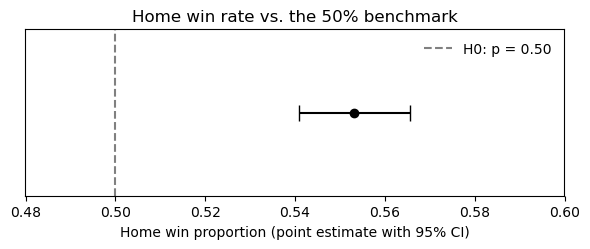

In [4]:

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.errorbar(p_hat, 0, xerr=1.96 * se_hat, fmt="o", color="black", capsize=6)
ax.axvline(0.5, color="gray", linestyle="--", label="H0: p = 0.50")
ax.set_yticks([]); ax.set_xlim(0.48, 0.60)
ax.set_xlabel("Home win proportion (point estimate with 95% CI)")
ax.set_title("Home win rate vs. the 50% benchmark")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()


**Interpretation:** Home teams won 55.3% of the 6,144 games (3,399 wins). The test statistic is z = 8.34 with a one-sided p-value of about 3.60e-17 (basically zero), so we reject H0: a 50% home win rate is not consistent with this data. The 95% confidence interval for the true home win rate is roughly **54.1% to 56.6%**; it excludes 50% and shows the advantage is real but modest about 4 to 7 percentage points.

**Scope and caution:** This is evidence of an **association** between playing at home and winning. It does not identify why (crowd, travel, rest, officiating). It covers only the 2021-22 to 2025-26 regular seasons, so it should not be generalized to other eras or to playoff games.

## Prediction: Can a home team's result be predicted before the game?

**Target:** `home_win` = 1 if the home team won, else 0 this is classification.

**Predictors and how leakage is avoided.** Same-game statistics (FG%, turnovers, points) are only known after a game, so they cannot be used to predict it. I use only each team's **previous-season** record: win percentage and average point margin. These are fully known before the first game of the season, so no feature ever comes from the game being predicted, or from any game in the same season as the test games. I use the home minus away difference of each.

**Preprocessing:** assign each game to a season, attach each team's previous-season record, and drop 2021-22 since the data has no earlier season to look back on.

**Split:** by season rather than at random. Train on 2022-23 through 2024-25 and test on 2025-26, so the model is always tested on a later season than it learned from.

**Baseline:** always predict the most common training outcome (home win).
**Models:** logistic regression (simple, interpretable) and a random forest (non-linear).

In [5]:
# For games starting in Sep of the year 
d["season"] = np.where(d["gameDate"].dt.month >= 9, d["gameDate"].dt.year, d["gameDate"].dt.year - 1)
d["margin"] = d["teamScore"] - d["opponentScore"]

# Each team’s previous season win percentage and average margin of victory
prev_season = (d.groupby(["teamId", "season"])
          .agg(prev_win_pct=("win", "mean"), prev_margin=("margin", "mean"))
          .reset_index())
prev_season["season"] += 1
d = d.merge(prev_season, on=["teamId", "season"], how="left")

# Home vs Away
H = d[d["home"] == 1].set_index("gameId")
A = d[d["home"] == 0].set_index("gameId")
common = H.index.intersection(A.index)
H, A = H.loc[common], A.loc[common]

# Create new dataframe 

X = pd.DataFrame({
    "diff_prev_win_pct": H["prev_win_pct"] - A["prev_win_pct"],
    "diff_prev_margin":  H["prev_margin"] - A["prev_margin"],
    "home_prev_win_pct": H["prev_win_pct"],
    "away_prev_win_pct": A["prev_win_pct"],
})
X["season"] = H["season"]
y = H["win"].astype(int).rename("home_win")


ok = X.dropna().index                       # drops 2021-22 (no previous season)
X, y = X.loc[ok], y.loc[ok]
print("Games with a previous-season record:", len(X))
print(X["season"].value_counts().sort_index().to_string())

Games with a previous-season record: 4914
season
2022    1230
2023    1230
2024    1224
2025    1230


In [6]:
# implement train test split on time, train on 2021-2024 and test on 2025-2026

# for 2022-23, 2023-24, 2024-25
train = X["season"] < 2025            
X_train, X_test = X.loc[train].drop(columns="season"), X.loc[~train].drop(columns="season")
y_train, y_test = y.loc[train], y.loc[~train]
print(f"Train: {len(X_train):,} games | Test (2025-26): {len(X_test):,} games")
print(f"Home-win rate: train {y_train.mean():.3f} | test {y_test.mean():.3f}")

Train: 3,684 games | Test (2025-26): 1,230 games
Home-win rate: train 0.556 | test 0.554


In [7]:
# implement models 
logreg_cols = ["diff_prev_win_pct", "diff_prev_margin"]
models = {
    "Baseline (always home win)": (DummyClassifier(strategy="most_frequent"), logreg_cols),
    "Logistic regression":        (LogisticRegression(max_iter=1000), logreg_cols),
    "Random forest":              (RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                          random_state=42), list(X_train.columns)),
}
rows, fitted = [], {}
for name, (m, cols) in models.items():
    m.fit(X_train[cols], y_train)
    pred, prob = m.predict(X_test[cols]), m.predict_proba(X_test[cols])[:, 1]
    fitted[name] = (pred, prob)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "ROC AUC": roc_auc_score(y_test, prob),
                 "F1": f1_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results


,Accuracy,ROC AUC,F1
Model,,,
Baseline (always home win),0.554,0.500,0.713
Logistic regression,0.603,0.633,0.667
Random forest,0.584,0.606,0.649


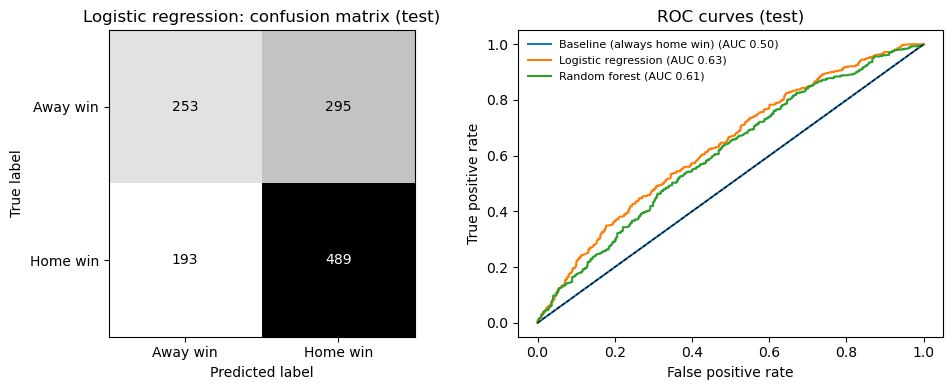

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, fitted["Logistic regression"][0]),
                       display_labels=["Away win", "Home win"]).plot(ax=ax[0], cmap="Greys", colorbar=False)
ax[0].set_title("Logistic regression: confusion matrix (test)")

for name, (pred, prob) in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves (test)"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
lr = models["Logistic regression"][0]
print(pd.Series(lr.coef_[0], index=logreg_cols).round(3).to_string())

diff_prev_win_pct    1.527
diff_prev_margin     0.030


## Evaluation

**Metrics:** This is a classification task, so I report accuracy, ROC AUC and F1 on the held-out 2025-26 games and compare each model with the baseline.

**Results:** The baseline is correct about 55.4% of the time  meaning that it predicts the home team to win every game and has no ranking ability (AUC 0.50). Logistic regression reaches **60.3% accuracy and AUC 0.63**, about 5 percentage points above the baseline. The random forest does slightly worse (58.4%, AUC 0.61), thus the simpler logistic regression is preferred.

**NB F1:** The baseline's F1 is high because it predicts home win for every game, which maximizes F1 for the home-win class. Accuracy and AUC are the more informative comparisons.

**Limitations and bias**
- Using only last season's record is a rough proxy: it misses trades, injuries, rookies and teams that improve or decline during the season.
- The logistic regression's errors are lopsided: it predicts a home win for 295 games the away team won, versus 193 home wins it called for the away team, reflecting the home-team tilt in the data.
- The test set is a single season, so the accuracy estimate is noisy and may not hold in other seasons.
- 2021-22 is excluded because it has no previous season, which shrinks the data.
- Previous-season win percentage and point margin are strongly related, so their coefficients should not be interpreted separately.

## Synthesis

- **EDA in Assignment 1:** showed winners shoot better, assist more and turn the ball over less, with field goal percentage most correlated with scoring (r = 0.73), and home teams winning more often.
- **Inference:** confirmed the home advantage is statistically distinguishable from 50% (about 54% to 57%), but small.
- **Prediction:** showed that last season's record gives a modest forecast (about 60% accuracy vs. 55% for the baseline). The in-game statistics that explained winning in the EDA cannot be used for prediction because they are only known after the game.
- **Association, not causation:** none of these results show WHY teams win. Home court and past performance are associated with winning, but the data cannot separate cause from effect.